<a href="https://colab.research.google.com/github/SithmiDesilva/Hallucination-Aware-AI-Framework-for-Trustworthy-Supply-Chain-Decision-Intelligence.-/blob/DataCo_Supply_Chain_Preprocessing/DataCo_tokenized_access_logs_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## SECTION 1: INITIAL SETUP AND DATA LOADING

In [6]:
# ============================================================================
# SECTION 1: SETUP, INSTALLATION & DATA LOADING
# ============================================================================

# Install required packages
!pip install pandas numpy matplotlib seaborn wordcloud -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from collections import Counter
import re
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# File path
file_path = '/content/drive/MyDrive/IRP/Data Co/tokenized_access_logs.csv'

# Load data
try:
    df_raw = pd.read_csv(file_path, encoding='utf-8', low_memory=False)
    print(f"\n Data loaded successfully!")
    print(f"  - Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
    print(f"  - Columns: {list(df_raw.columns)}")
except FileNotFoundError:
    print(f"\n File not found at: {file_path}")
    print("Please upload the file:")
    from google.colab import files
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
    df_raw = pd.read_csv(filename, encoding='utf-8', low_memory=False)
    print(f"\n Data loaded from upload!")
    print(f"  - Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
except Exception as e:
    print(f"\n Error: {e}")
    df_raw = None

# Quick preview
if df_raw is not None:
    print("\n--- First 5 Rows ---")
    display(df_raw.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 Data loaded successfully!
  - Shape: 469,977 rows × 8 columns
  - Columns: ['Product', 'Category', 'Date', 'Month', 'Hour', 'Department', 'ip', 'url']

--- First 5 Rows ---


,Product,Category,Date,Month,Hour,Department,ip,url
0,adidas Brazuca 2017 Official Match Ball,baseball & softball,9/1/2017 6:00,Sep,6,fitness,37.97.182.65,/department/fitness/category/baseball%20&%20so...
1,The North Face Women's Recon Backpack,hunting & shooting,9/1/2017 6:00,Sep,6,fan shop,206.56.112.1,/department/fan%20shop/category/hunting%20&%20...
2,adidas Kids' RG III Mid Football Cleat,featured shops,9/1/2017 6:00,Sep,6,apparel,215.143.180.0,/department/apparel/category/featured%20shops/...
3,Under Armour Men's Compression EV SL Slide,electronics,9/1/2017 6:00,Sep,6,footwear,206.56.112.1,/department/footwear/category/electronics/prod...
4,Pelican Sunstream 100 Kayak,water sports,9/1/2017 6:01,Sep,6,fan shop,136.108.56.242,/department/fan%20shop/category/water%20sports...


## SECTION 2: INITIAL DATA INSPECTION (BEFORE PREPROCESSING)

In [7]:
# 2.1 Data Types & Memory
print("\n--- Data Types & Memory Usage ---")
df_raw.info()


--- Data Types & Memory Usage ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 469977 entries, 0 to 469976
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Product     469977 non-null  object
 1   Category    469977 non-null  object
 2   Date        469977 non-null  object
 3   Month       469977 non-null  object
 4   Hour        469977 non-null  int64 
 5   Department  469977 non-null  object
 6   ip          469977 non-null  object
 7   url         469977 non-null  object
dtypes: int64(1), object(7)
memory usage: 28.7+ MB


In [8]:
# 2.2 Numerical Summary
print("\n--- Numerical Columns Summary ---")
numerical_cols = df_raw.select_dtypes(include=['float64', 'int64']).columns
if len(numerical_cols) > 0:
    display(df_raw[numerical_cols].describe())
else:
    print("No numerical columns found")


--- Numerical Columns Summary ---


,Hour
count,469977.000000
mean,14.591827
std,5.574014
min,0.000000
25%,10.000000
50%,15.000000
75%,20.000000
max,23.000000


In [10]:
# 2.3 Missing Values

missing_df = pd.DataFrame({
    'Column': df_raw.columns,
    'Missing_Count': df_raw.isnull().sum(),
    'Missing_Pct': (df_raw.isnull().sum() / len(df_raw)) * 100
}).sort_values('Missing_Pct', ascending=False)
print(missing_df[missing_df['Missing_Count'] > 0])
if len(missing_df[missing_df['Missing_Count'] > 0]) == 0:
    print(" No missing values found")

Empty DataFrame
Columns: [Column, Missing_Count, Missing_Pct]
Index: []
 No missing values found


In [11]:
# 2.4 Sample data
print("\n--- Sample Data (10 rows) ---")
display(df_raw.head(10))


--- Sample Data (10 rows) ---


,Product,Category,Date,Month,Hour,Department,ip,url
0,adidas Brazuca 2017 Official Match Ball,baseball & softball,9/1/2017 6:00,Sep,6,fitness,37.97.182.65,/department/fitness/category/baseball%20&%20so...
1,The North Face Women's Recon Backpack,hunting & shooting,9/1/2017 6:00,Sep,6,fan shop,206.56.112.1,/department/fan%20shop/category/hunting%20&%20...
2,adidas Kids' RG III Mid Football Cleat,featured shops,9/1/2017 6:00,Sep,6,apparel,215.143.180.0,/department/apparel/category/featured%20shops/...
3,Under Armour Men's Compression EV SL Slide,electronics,9/1/2017 6:00,Sep,6,footwear,206.56.112.1,/department/footwear/category/electronics/prod...
4,Pelican Sunstream 100 Kayak,water sports,9/1/2017 6:01,Sep,6,fan shop,136.108.56.242,/department/fan%20shop/category/water%20sports...
5,Team Golf Tennessee Volunteers Putter Grip,accessories,9/1/2017 6:02,Sep,6,outdoors,116.202.25.156,/department/outdoors/category/accessories/prod...
6,The North Face Women's Recon Backpack,hunting & shooting,9/1/2017 6:02,Sep,6,fan shop,131.132.236.70,/department/fan%20shop/category/hunting%20&%20...
7,Diamondback Boys' Insight 24 Performance Hybr,basketball,9/1/2017 6:02,Sep,6,fitness,30.175.101.147,/department/fitness/category/basketball/produc...
8,Nike Men's Dri-FIT Victory Golf Polo,women's apparel,9/1/2017 6:03,Sep,6,golf,206.56.112.1,/department/golf/category/women's%20apparel/pr...
9,adidas Kids' RG III Mid Football Cleat,featured shops,9/1/2017 6:03,Sep,6,apparel,171.218.47.35,/department/apparel/category/featured%20shops/...


In [12]:
# 2.5 Unique values per object column
print("\n--- Cardinality of Object Columns ---")
obj_cols = df_raw.select_dtypes(include=['object']).columns
cardinality = pd.DataFrame({
    'Column': obj_cols,
    'Unique_Values': [df_raw[c].nunique() for c in obj_cols],
    'Sample': [df_raw[c].dropna().iloc[0] if df_raw[c].notna().any() else 'N/A' for c in obj_cols]
})
display(cardinality)


--- Cardinality of Object Columns ---


,Column,Unique_Values,Sample
0,Product,76,adidas Brazuca 2017 Official Match Ball
1,Category,33,baseball & softball
2,Date,160815,9/1/2017 6:00
3,Month,5,Sep
4,Department,6,fitness
5,ip,3340,37.97.182.65
6,url,152,/department/fitness/category/baseball%20&%20so...


## SECTION 3: BEFORE PREPROCESSING VISUALIZATIONS

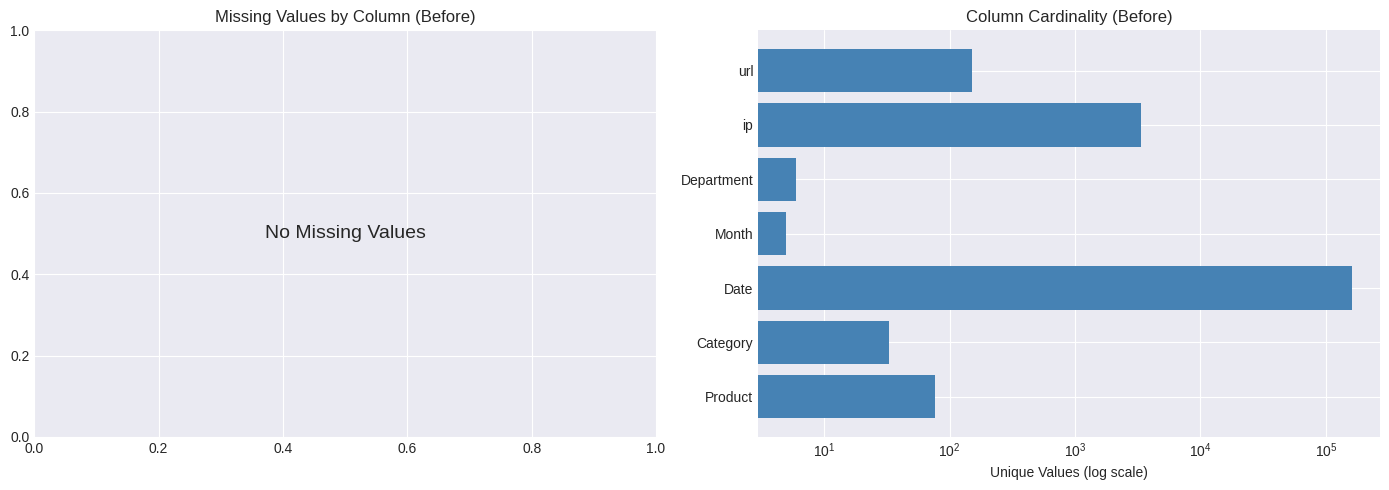

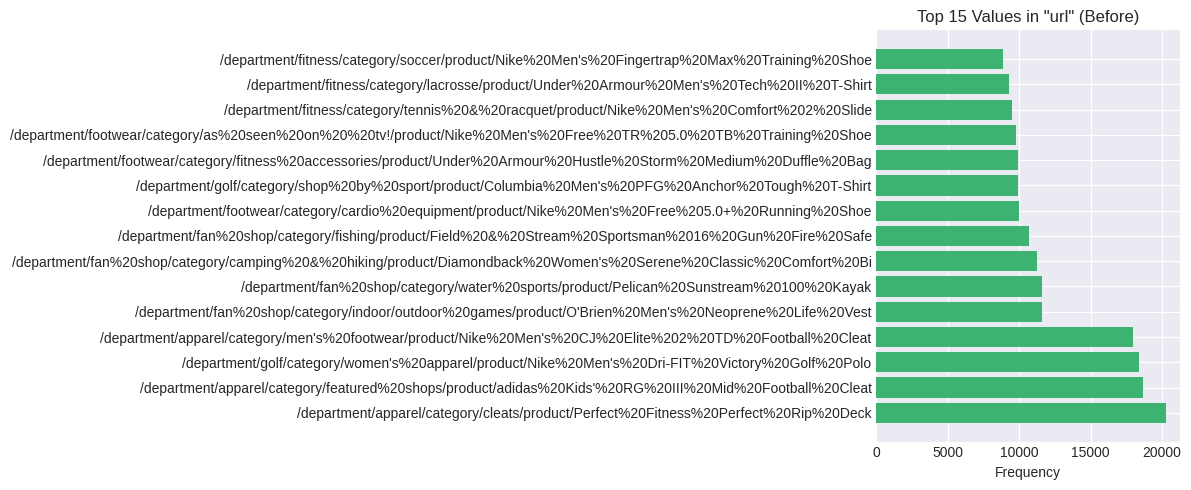

In [16]:

plt.style.use('seaborn-v0_8-darkgrid')

# 3.1 Missing values bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

missing_nonzero = missing_df[missing_df['Missing_Count'] > 0]
if len(missing_nonzero) > 0:
    axes[0].barh(missing_nonzero['Column'], missing_nonzero['Missing_Pct'], color='coral')
    axes[0].set_xlabel('Missing %')
    axes[0].set_title('Missing Values by Column (Before)')
else:
    axes[0].text(0.5, 0.5, 'No Missing Values', ha='center', va='center', fontsize=14)
    axes[0].set_title('Missing Values by Column (Before)')

# 3.2 Column cardinality
axes[1].barh(cardinality['Column'], cardinality['Unique_Values'], color='steelblue')
axes[1].set_xlabel('Unique Values (log scale)')
axes[1].set_title('Column Cardinality (Before)')
axes[1].set_xscale('log')

plt.tight_layout()
plt.savefig('section3_before_preprocessing.png', dpi=120, bbox_inches='tight')
plt.show()

# 3.3 Raw URL/column value distribution (if URL-like column exists)
url_col = None
for col in df_raw.columns:
    if any(kw in col.lower() for kw in ['url', 'page', 'path', 'uri', 'link']):
        url_col = col
        break

if url_col:
    fig, ax = plt.subplots(figsize=(12, 5))
    top_vals = df_raw[url_col].value_counts().head(15)
    ax.barh(top_vals.index.astype(str), top_vals.values, color='mediumseagreen')
    ax.set_title(f'Top 15 Values in "{url_col}" (Before)')
    ax.set_xlabel('Frequency')
    plt.tight_layout()
    plt.savefig('section3_url_distribution.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print("No URL-like column found for distribution plot")

## SECTION 4: SAMPLING FOR EFFICIENCY

In [17]:
SAMPLE_SIZE = 20000

if df_raw is not None:
    if len(df_raw) > SAMPLE_SIZE:
        df = df_raw.sample(SAMPLE_SIZE, random_state=42).reset_index(drop=True)
        print(f" Sampled {SAMPLE_SIZE:,} rows from {len(df_raw):,} total")
    else:
        df = df_raw.copy()
        print(f" Using full dataset ({len(df):,} rows)")

    print(f"\nWorking dataframe shape: {df.shape}")
    display(df.head(3))
else:
    df = None
    print(" No data to sample")

 Sampled 20,000 rows from 469,977 total

Working dataframe shape: (20000, 8)


,Product,Category,Date,Month,Hour,Department,ip,url
0,Nike Men's Dri-FIT Victory Golf Polo,women's apparel,9/28/2017 2:59,Sep,2,golf,70.101.216.88,/department/golf/category/women's%20apparel/pr...
1,Field & Stream Sportsman 16 Gun Fire Safe,fishing,10/13/2017 23:35,Oct,23,fan shop,61.237.4.104,/department/fan%20shop/category/fishing/produc...
2,Under Armour Men's Tech II T-Shirt,lacrosse,11/10/2017 13:51,Nov,13,fitness,44.244.189.251,/department/fitness/category/lacrosse/product/...


## SECTION 5: URL PARSING

In [19]:
# 5.1 Identify URL column
url_col = None
possible_url_cols = ['url', 'page', 'path', 'link', 'request_uri', 'uri', 'resource']
for col in df.columns:
    for possible in possible_url_cols:
        if possible in col.lower():
            url_col = col
            break
    if url_col:
        break

if url_col is None:
    obj_cols = df.select_dtypes(include=['object']).columns
    url_col = obj_cols[0] if len(obj_cols) > 0 else None
    print(f" Fallback to first object column: {url_col}")
else:
    print(f" URL column identified: {url_col}")

# 5.2 Parse function
def parse_url(url):
    if pd.isna(url):
        return {'department': None, 'category': None, 'subcategory': None, 'product': None}
    s = str(url)
    return {
        'department': (re.search(r'/department/([^/]+)', s) or [None, None])[1],
        'category':   (re.search(r'/category/([^/]+)',   s) or [None, None])[1],
        'subcategory':(re.search(r'/subcategory/([^/]+)',s) or [None, None])[1],
        'product':    (re.search(r'/product/([^/]+)',    s) or [None, None])[1],
    }

if url_col:
    parsed = df[url_col].apply(parse_url)
    df['parsed_department']  = parsed.apply(lambda x: x['department'])
    df['parsed_category']    = parsed.apply(lambda x: x['category'])
    df['parsed_subcategory'] = parsed.apply(lambda x: x['subcategory'])
    df['parsed_product']     = parsed.apply(lambda x: x['product'])

    print("\n--- Parsing Results ---")
    for c in ['parsed_department', 'parsed_category', 'parsed_subcategory', 'parsed_product']:
        n = df[c].notna().sum()
        print(f"  {c}: {n:,} non-null ({n/len(df)*100:.1f}%), {df[c].nunique()} unique")

    # Preview parsed columns
    print("\n--- Sample Parsed Data ---")
    display(df[[url_col, 'parsed_department', 'parsed_category', 'parsed_product']].head(10))

 URL column identified: url

--- Parsing Results ---
  parsed_department: 20,000 non-null (100.0%), 6 unique
  parsed_category: 20,000 non-null (100.0%), 33 unique
  parsed_subcategory: 0 non-null (0.0%), 0 unique
  parsed_product: 20,000 non-null (100.0%), 76 unique

--- Sample Parsed Data ---


,url,parsed_department,parsed_category,parsed_product
0,/department/golf/category/women's%20apparel/pr...,golf,women's%20apparel,Nike%20Men's%20Dri-FIT%20Victory%20Golf%20Polo
1,/department/fan%20shop/category/fishing/produc...,fan%20shop,fishing,Field%20&%20Stream%20Sportsman%2016%20Gun%20Fi...
2,/department/fitness/category/lacrosse/product/...,fitness,lacrosse,Under%20Armour%20Men's%20Tech%20II%20T-Shirt
3,/department/apparel/category/featured%20shops/...,apparel,featured%20shops,adidas%20Kids'%20RG%20III%20Mid%20Football%20C...
4,/department/footwear/category/cardio%20equipme...,footwear,cardio%20equipment,Nike%20Men's%20Free%205.0+%20Running%20Shoe
5,/department/fan%20shop/category/water%20sports...,fan%20shop,water%20sports,Pelican%20Sunstream%20100%20Kayak
6,/department/fitness/category/tennis%20&%20racq...,fitness,tennis%20&%20racquet,Nike%20Men's%20Comfort%202%20Slide
7,/department/apparel/category/men's%20footwear/...,apparel,men's%20footwear,Nike%20Men's%20CJ%20Elite%202%20TD%20Football%...
8,/department/golf/category/shop%20by%20sport/pr...,golf,shop%20by%20sport,Under%20Armour%20Girls'%20Toddler%20Spine%20Su...
9,/department/apparel/category/men's%20footwear/...,apparel,men's%20footwear,Nike%20Men's%20CJ%20Elite%202%20TD%20Football%...


## SECTION 6: DATE PARSING AND TEMPORAL FEATURES

In [20]:
# 6.1 Identify date columns
date_keywords = ['date', 'time', 'timestamp', 'day', 'month', 'year', 'datetime']
date_cols = [c for c in df.columns if any(k in c.lower() for k in date_keywords)]
print(f"Date columns found: {date_cols}")

# 6.2 Parse
if date_cols:
    col = date_cols[0]
    df[f'{col}_parsed'] = pd.to_datetime(df[col], errors='coerce')
    valid_dates = df[f'{col}_parsed'].notna().sum()
    print(f" Parsed '{col}': {valid_dates:,} valid dates ({valid_dates/len(df)*100:.1f}%)")

    if valid_dates > 0:
        df['visit_year']    = df[f'{col}_parsed'].dt.year
        df['visit_month']   = df[f'{col}_parsed'].dt.month
        df['visit_day']     = df[f'{col}_parsed'].dt.day
        df['visit_weekday'] = df[f'{col}_parsed'].dt.dayofweek
        df['visit_hour']    = df[f'{col}_parsed'].dt.hour

        print("\n--- Date Range ---")
        print(f"  Min: {df[f'{col}_parsed'].min()}")
        print(f"  Max: {df[f'{col}_parsed'].max()}")

        print("\n--- Temporal Feature Sample ---")
        display(df[['visit_year','visit_month','visit_day','visit_weekday','visit_hour']].head())
else:
    print(" No date columns found")
    for f in ['visit_year','visit_month','visit_day','visit_weekday','visit_hour']:
        df[f] = None

Date columns found: ['Date', 'Month']
 Parsed 'Date': 20,000 valid dates (100.0%)

--- Date Range ---
  Min: 2017-09-01 06:02:00
  Max: 2018-01-31 23:42:00

--- Temporal Feature Sample ---


,visit_year,visit_month,visit_day,visit_weekday,visit_hour
0,2017,9,28,3,2
1,2017,10,13,4,23
2,2017,11,10,4,13
3,2017,9,14,3,21
4,2017,12,11,0,11


## SECTION 8: SESSION ANALYSIS

[Columns Identified] User/IP: 'ip', Session: 'None', Time: 'Date'

--- Creating Synthetic Sessions (30-Minute Inactivity Threshold) ---

=== SESSION METRICS ===
  Total Reconstructed Sessions: 18,831
  Average Clicks per Session:   1.06 clicks
  Median Clicks per Session:    1 clicks
  Max Clicks in a Session:      6
  Average Session Duration:     0.66 minutes
  Bounce Rate (1-click visits): 94.55%

=== USER (IP) BEHAVIOR METRICS ===
  Unique Visitors (IPs):        2,963
  Average Activity per User:    6.75 interactions
  Top 1% Most Active Users own: 3.57% of total traffic


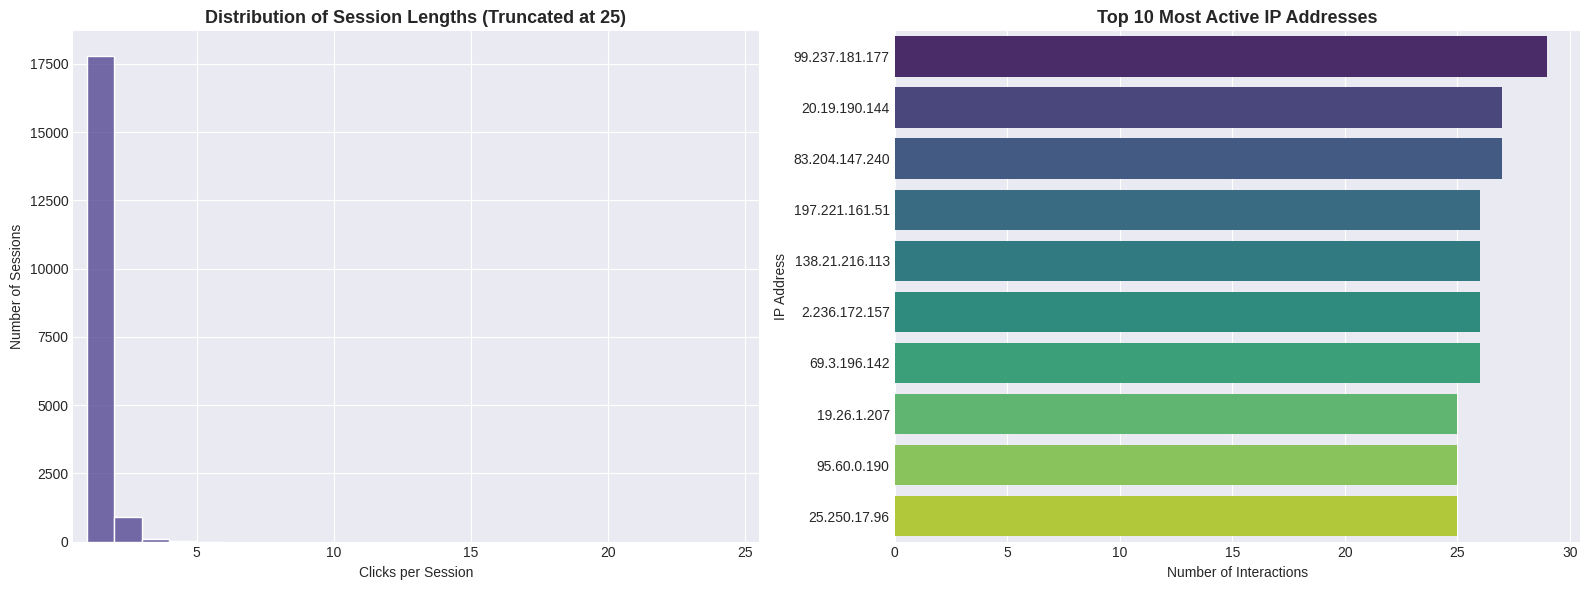

In [22]:
# 7.1 Identify session, user, and time columns using robust string matching
user_col = session_col = time_col = None
for c in df.columns:
    cl = c.lower()
    if any(k in cl for k in ['user','visitor','customer','ip']) and not user_col:
        user_col = c
    elif any(k in cl for k in ['session_id', 'visit_id']) and not session_col:
        session_col = c
    elif any(k in cl for k in ['time','date','timestamp']) and '_parsed' not in cl and not time_col:
        time_col = c

print(f"[Columns Identified] User/IP: '{user_col}', Session: '{session_col}', Time: '{time_col}'")

# 7.2 Reconstruct Session IDs and Compute Metrics
# If session_col is not a true session ID (e.g., if it wrongly matched visit_year), build sessions from IP + Time gaps
if not session_col or df[session_col].nunique() <= 5:
    if user_col and f'{time_col}_parsed' in df.columns:
        print("\n--- Creating Synthetic Sessions (30-Minute Inactivity Threshold) ---")
        # Sort by user and timestamp to compute gaps
        df = df.sort_values(by=[user_col, f'{time_col}_parsed']).reset_index(drop=True)
        time_diff = df.groupby(user_col)[f'{time_col}_parsed'].diff()

        # Standard web session definition: inactivity gap > 30 minutes (1800s)
        is_new_session = (time_diff.isnull()) | (time_diff.dt.total_seconds() > 1800)
        df['session_id_created'] = df[user_col].astype(str) + '_' + is_new_session.groupby(df[user_col]).cumsum().astype(str)
        session_col_to_use = 'session_id_created'
    else:
        session_col_to_use = None
else:
    session_col_to_use = session_col

if session_col_to_use:
    # Calculate clicks per session
    session_lengths = df.groupby(session_col_to_use).size()
    df['session_length'] = df[session_col_to_use].map(session_lengths)

    # Session duration (time difference between last and first activity in session)
    session_times = df.groupby(session_col_to_use)[f'{time_col}_parsed'].agg(['min', 'max'])
    session_durations = (session_times['max'] - session_times['min']).dt.total_seconds() / 60.0
    df['session_duration_minutes'] = df[session_col_to_use].map(session_durations)

    # Calculate key aggregates
    bounce_rate = (session_lengths == 1).mean() * 100

    print(f"\n=== SESSION METRICS ===")
    print(f"  Total Reconstructed Sessions: {len(session_lengths):,}")
    print(f"  Average Clicks per Session:   {session_lengths.mean():.2f} clicks")
    print(f"  Median Clicks per Session:    {session_lengths.median():.0f} clicks")
    print(f"  Max Clicks in a Session:      {session_lengths.max():,}")
    print(f"  Average Session Duration:     {session_durations.mean():.2f} minutes")
    print(f"  Bounce Rate (1-click visits): {bounce_rate:.2f}%")
else:
    print("\n[Error] Unable to perform session analysis: Missing User or parsed DateTime columns.")

# 7.3 User Frequency and Concentration analysis
if user_col:
    user_freq = df[user_col].value_counts()
    print(f"\n=== USER (IP) BEHAVIOR METRICS ===")
    print(f"  Unique Visitors (IPs):        {len(user_freq):,}")
    print(f"  Average Activity per User:    {user_freq.mean():.2f} interactions")
    print(f"  Top 1% Most Active Users own: {user_freq.head(int(len(user_freq)*0.01)).sum() / len(df) * 100:.2f}% of total traffic")

# 7.4 Multi-panel Visualizations
if session_col_to_use and user_col:
    plt.style.use('seaborn-v0_8-darkgrid')
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Panel 1: Distribution of Clicks per Session
    sns.histplot(session_lengths, bins=range(1, min(25, session_lengths.max()) + 1),
                 kde=False, color='darkslateblue', ax=axes[0], edgecolor='white')
    axes[0].set_title('Distribution of Session Lengths (Truncated at 25)', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Clicks per Session')
    axes[0].set_ylabel('Number of Sessions')
    axes[0].set_xlim(0.5, 25.5)

    # Panel 2: Highly active IPs
    top_ips = user_freq.head(10)
    sns.barplot(x=top_ips.values, y=top_ips.index, ax=axes[1], palette='viridis', hue=top_ips.index, legend=False)
    axes[1].set_title('Top 10 Most Active IP Addresses', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Number of Interactions')
    axes[1].set_ylabel('IP Address')

    plt.tight_layout()
    plt.savefig('section7_session_insights.png', dpi=120, bbox_inches='tight')
    plt.show()

## SECTION 8: CATEGORY ANALYSIS

=== 1. CATEGORICAL HIERARCHY INTEGRITY CHECK ===
  Department Matching (Native vs. Parsed): 0.00% matched
  Category Matching (Native vs. Parsed): 96.56% matched

=== 2. DEPARTMENT ENGAGEMENT & PRODUCT DIVERSITY ===


,Department,interactions,unique_categories,unique_products,traffic_share_%
0,apparel,"3,408",3,3,17.04%
5,outdoors,"3,378",11,42,16.89%
1,fan shop,"3,346",5,6,16.73%
3,footwear,"3,324",6,10,16.62%
2,fitness,"3,293",6,9,16.46%
4,golf,"3,251",3,6,16.25%



=== 3. DOMINANT PRODUCT PER DEPARTMENT ===


,Department,Top Product,Interactions,Share Within Dept %
2,apparel,Perfect Fitness Perfect Rip Deck,"1,167",34.24%
3,golf,Nike Men's Dri-FIT Victory Golf Polo,"1,125",34.60%
1,fan shop,Field & Stream Sportsman 16 Gun Fire Safe,699,20.89%
4,footwear,Under Armour Hustle Storm Medium Duffle Bag,589,17.72%
5,fitness,Nike Men's Comfort 2 Slide,588,17.86%
0,outdoors,Ogio Race Golf Shoes,332,9.83%


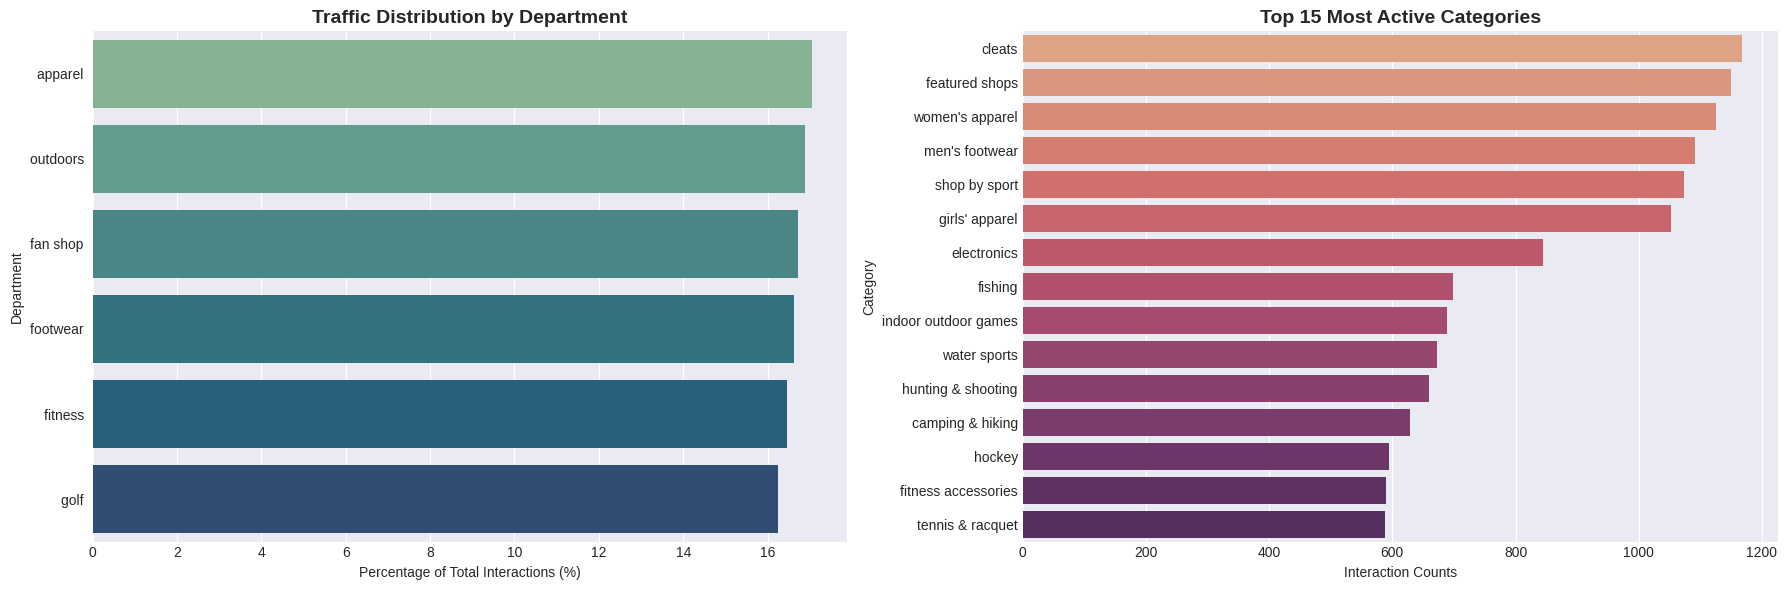

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

print("=== 1. CATEGORICAL HIERARCHY INTEGRITY CHECK ===")
# Let's verify if the native Department/Category columns align perfectly with our URL parsed fields
if 'parsed_department' in df.columns and 'Department' in df.columns:
    # Clean and match strings (lowercasing and stripping spacing/symbols for proper comparison)
    native_dept = df['Department'].str.lower().str.replace(' ', '%20')
    parsed_dept = df['parsed_department'].str.lower()
    match_rate = (native_dept == parsed_dept).mean() * 100
    print(f"  Department Matching (Native vs. Parsed): {match_rate:.2f}% matched")

if 'parsed_category' in df.columns and 'Category' in df.columns:
    native_cat = df['Category'].str.lower().str.replace(' ', '%20')
    parsed_cat = df['parsed_category'].str.lower()
    match_rate = (native_cat == parsed_cat).mean() * 100
    print(f"  Category Matching (Native vs. Parsed): {match_rate:.2f}% matched\n")

print("=== 2. DEPARTMENT ENGAGEMENT & PRODUCT DIVERSITY ===")
# Analyze product variety and traffic share for each department
dept_summary = df.groupby('Department').agg(
    interactions=('Product', 'count'),
    unique_categories=('Category', 'nunique'),
    unique_products=('Product', 'nunique')
).reset_index()

dept_summary['traffic_share_%'] = (dept_summary['interactions'] / len(df)) * 100
display(dept_summary.sort_values(by='interactions', ascending=False).style.format({
    'interactions': '{:,}',
    'traffic_share_%': '{:.2f}%'
}))

print("\n=== 3. DOMINANT PRODUCT PER DEPARTMENT ===")
# Find the absolute top product for every single department
top_products = []
for dept in df['Department'].unique():
    dept_df = df[df['Department'] == dept]
    if len(dept_df) > 0:
        top_prod = dept_df['Product'].value_counts().idxmax()
        top_count = dept_df['Product'].value_counts().max()
        top_products.append({
            'Department': dept,
            'Top Product': top_prod,
            'Interactions': top_count,
            'Share Within Dept %': (top_count / len(dept_df)) * 100
        })

display(pd.DataFrame(top_products).sort_values(by='Interactions', ascending=False).style.format({
    'Interactions': '{:,}',
    'Share Within Dept %': '{:.2f}%'
}))

# === 4. VISUALIZATION ===
plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left Panel: Traffic Share by Department
sns.barplot(
    x='traffic_share_%',
    y='Department',
    data=dept_summary.sort_values(by='traffic_share_%', ascending=False),
    ax=axes[0],
    palette='crest',
    hue='Department',
    legend=False
)
axes[0].set_title('Traffic Distribution by Department', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Percentage of Total Interactions (%)')
axes[0].set_ylabel('Department')

# Right Panel: Top 15 Highly Clicked Categories
top_categories = df['Category'].value_counts().head(15).reset_index()
sns.barplot(
    x='count',
    y='Category',
    data=top_categories,
    ax=axes[1],
    palette='flare',
    hue='Category',
    legend=False
)
axes[1].set_title('Top 15 Most Active Categories', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Interaction Counts')
axes[1].set_ylabel('Category')

plt.tight_layout()
plt.savefig('section8_categorical_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

## SECTION 9: AFTER PREPROCESSING VISUALIZATIONS

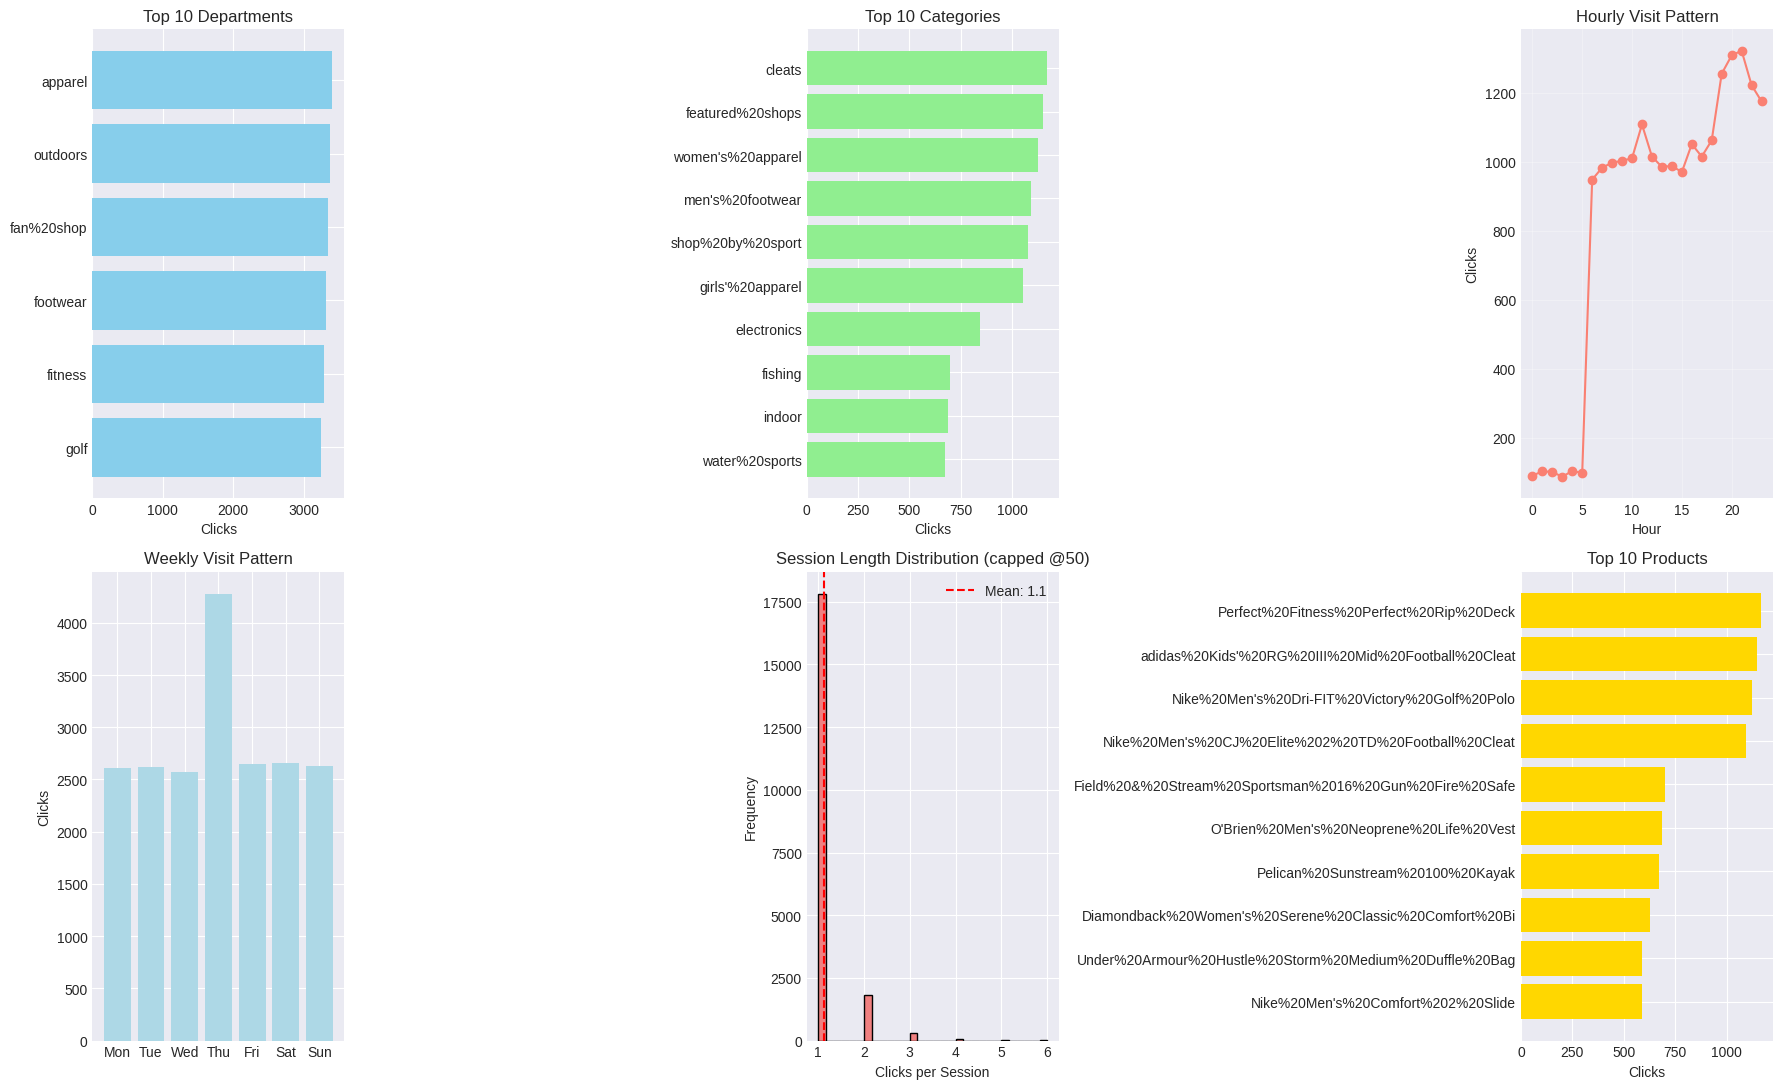

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# 9.1 Department distribution
if 'parsed_department' in df.columns and df['parsed_department'].notna().any():
    top = df['parsed_department'].value_counts().head(10)
    axes[0,0].barh(top.index, top.values, color='skyblue')
    axes[0,0].set_title('Top 10 Departments')
    axes[0,0].set_xlabel('Clicks')
    axes[0,0].invert_yaxis()
else:
    axes[0,0].text(0.5, 0.5, 'No Data', ha='center', va='center')

# 9.2 Category distribution
if 'parsed_category' in df.columns and df['parsed_category'].notna().any():
    top = df['parsed_category'].value_counts().head(10)
    axes[0,1].barh(top.index, top.values, color='lightgreen')
    axes[0,1].set_title('Top 10 Categories')
    axes[0,1].set_xlabel('Clicks')
    axes[0,1].invert_yaxis()
else:
    axes[0,1].text(0.5, 0.5, 'No Data', ha='center', va='center')

# 9.3 Hourly pattern
if 'visit_hour' in df.columns and df['visit_hour'].notna().any():
    hc = df['visit_hour'].value_counts().sort_index()
    axes[0,2].plot(hc.index, hc.values, marker='o', color='salmon')
    axes[0,2].set_title('Hourly Visit Pattern')
    axes[0,2].set_xlabel('Hour')
    axes[0,2].set_ylabel('Clicks')
    axes[0,2].grid(True, alpha=0.3)
else:
    axes[0,2].text(0.5, 0.5, 'No Data', ha='center', va='center')

# 9.4 Weekday pattern
if 'visit_weekday' in df.columns and df['visit_weekday'].notna().any():
    labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
    wc = df['visit_weekday'].value_counts().sort_index()
    axes[1,0].bar([labels[i] for i in wc.index], wc.values, color='lightblue')
    axes[1,0].set_title('Weekly Visit Pattern')
    axes[1,0].set_ylabel('Clicks')
else:
    axes[1,0].text(0.5, 0.5, 'No Data', ha='center', va='center')

# 9.5 Session length distribution
if 'session_length' in df.columns and df['session_length'].notna().any():
    axes[1,1].hist(df['session_length'].clip(upper=50), bins=30, color='lightcoral', edgecolor='black')
    axes[1,1].set_title('Session Length Distribution (capped @50)')
    axes[1,1].set_xlabel('Clicks per Session')
    axes[1,1].set_ylabel('Frequency')
    axes[1,1].axvline(df['session_length'].mean(), color='red', ls='--',
                      label=f'Mean: {df["session_length"].mean():.1f}')
    axes[1,1].legend()
else:
    axes[1,1].text(0.5, 0.5, 'No Data', ha='center', va='center')

# 9.6 Top products
if 'parsed_product' in df.columns and df['parsed_product'].notna().any():
    top = df['parsed_product'].value_counts().head(10)
    axes[1,2].barh(top.index.astype(str), top.values, color='gold')
    axes[1,2].set_title('Top 10 Products')
    axes[1,2].set_xlabel('Clicks')
    axes[1,2].invert_yaxis()
else:
    axes[1,2].text(0.5, 0.5, 'No Data', ha='center', va='center')

plt.tight_layout()
plt.savefig('section9_after_preprocessing.png', dpi=120, bbox_inches='tight')
plt.show()



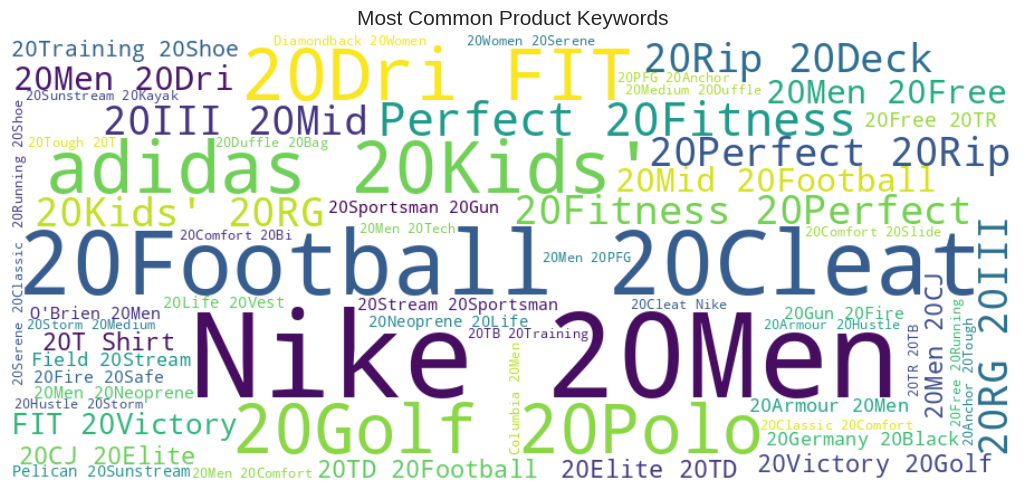

In [28]:
# 9.7 Word Cloud
if 'parsed_product' in df.columns:
    text = ' '.join(df['parsed_product'].dropna().astype(str))
    if len(text) > 100:
        try:
            wc = WordCloud(width=900, height=400, background_color='white',
                           max_words=60, colormap='viridis').generate(text)
            plt.figure(figsize=(12, 5))
            plt.imshow(wc, interpolation='bilinear')
            plt.axis('off')
            plt.title('Most Common Product Keywords', fontsize=15)
            plt.tight_layout()
            plt.savefig('section9_wordcloud.png', dpi=120, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Word cloud error: {e}")




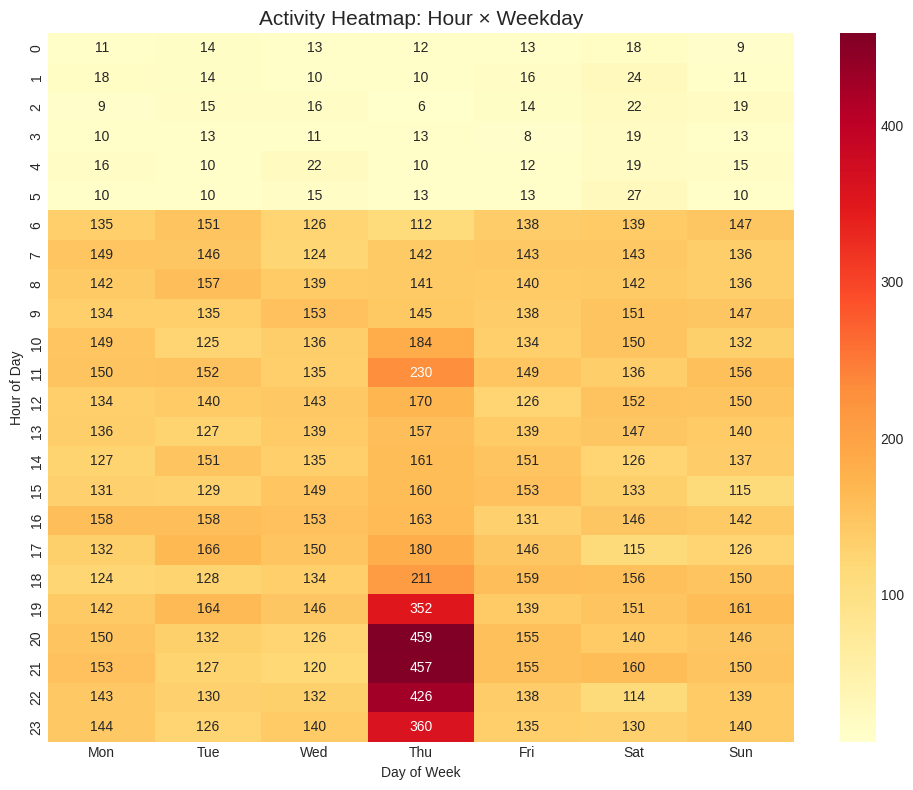

In [29]:
# 9.8 Activity heatmap
if 'visit_hour' in df.columns and 'visit_weekday' in df.columns:
    if df['visit_hour'].notna().any() and df['visit_weekday'].notna().any():
        heatmap = pd.crosstab(df['visit_hour'], df['visit_weekday'])
        labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
        plt.figure(figsize=(10, 8))
        sns.heatmap(heatmap, annot=True, fmt='d', cmap='YlOrRd',
                    xticklabels=labels, yticklabels=range(24))
        plt.title('Activity Heatmap: Hour × Weekday', fontsize=15)
        plt.xlabel('Day of Week')
        plt.ylabel('Hour of Day')
        plt.tight_layout()
        plt.savefig('section9_heatmap.png', dpi=120, bbox_inches='tight')
        plt.show()

## SECTION 10: KEY METRICS SUMMARY

In [32]:
metrics = {
    'Original Rows':            len(df_raw),
    'Working Rows (sampled)':   len(df),
    'Original Columns':         len(df_raw.columns),
    'Final Columns':            len(df.columns),
    'New Features Created':     len(df.columns) - len(df_raw.columns),
}

if url_col:
    for c in ['parsed_department','parsed_category','parsed_subcategory','parsed_product']:
        metrics[f'{c} (non-null)'] = int(df[c].notna().sum())

if 'session_length' in df.columns and df['session_length'].notna().any():
    metrics['Total Sessions']  = int(df['session_length'].notna().sum() / max(df['session_length'].mean(),1))
    metrics['Avg Session Length'] = round(df['session_length'].mean(), 2)

if user_col:
    metrics['Unique Users'] = int(df[user_col].nunique())

if 'visit_hour' in df.columns and df['visit_hour'].notna().any():
    metrics['Peak Hour'] = int(df['visit_hour'].mode().iloc[0])

if 'visit_weekday' in df.columns and df['visit_weekday'].notna().any():
    weekday_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
    metrics['Peak Weekday'] = weekday_names[int(df['visit_weekday'].mode().iloc[0])]

print("\n--- METRICS TABLE ---")
for k, v in metrics.items():
    print(f"  {k:.<35} {v}")


--- METRICS TABLE ---
  Original Rows...................... 469977
  Working Rows (sampled)............. 20000
  Original Columns................... 8
  Final Columns...................... 22
  New Features Created............... 14
  parsed_department (non-null)....... 20000
  parsed_category (non-null)......... 20000
  parsed_subcategory (non-null)...... 0
  parsed_product (non-null).......... 20000
  Total Sessions..................... 17639
  Avg Session Length................. 1.13
  Unique Users....................... 2963
  Peak Hour.......................... 21
  Peak Weekday....................... Thu
